In [17]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import make_column_selector,make_column_transformer
from sklearn.pipeline import Pipeline
import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score

In [6]:
# student = pd.read_csv("F:\MACHINE LEARNING\SessionsMaterial\Cases\student_performance\student_dataset_10000_rows.csv")
# X,y=student.drop('placement_status',axis=1),student['placement_status']
# X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=26,test_size=.3,stratify=y)
# student.head()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed


In [ ]:
# from sklearn.metrics import accuracy_score
# depths = [None, 2,3,4,5,6,7]
# min_split = [2,0.05,0.01,0.2,0.3]
# min_leaf = [1,5,10,20,50]
# scores = []
# for d in depths:
#     for s in min_split:
#         for f in min_leaf:
#             dtc = DecisionTreeClassifier(random_state=26, max_depth = d, min_samples_split= s, min_samples_leaf= f)
#             dtc.fit(X_train, y_train)
#             y_pred = dtc.predict(X_test)
#             scores.append([d, s, f, accuracy_score(y_test, y_pred)])
# df_scores = pd.DataFrame(scores, columns= ['depth','split','leaf','score'])
# df_scores.sort_values('score', ascending = False, ignore_index= True)

In [13]:
df=pd.read_csv("F:\MACHINE LEARNING\SessionsMaterial\Cases\human-resources-analytics\HR_comma_sep.csv")
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.10,0.77,6,247,4,0,1,0,sales,low
3,0.92,0.85,5,259,5,0,1,0,sales,low
4,0.89,1.00,5,224,5,0,1,0,sales,low


In [19]:
X,y=df.drop('left',axis=1),df.left
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.3,random_state=26, stratify = y)
ohe = OneHotEncoder(sparse_output= False).set_output(transform = 'pandas')
ct = make_column_transformer((ohe, make_column_selector(dtype_include=object)),
                            ('passthrough',make_column_selector(dtype_include = ['int64','float64'])),
                            verbose_feature_names_out=False)
ct=ct.set_output(transform='pandas')

In [20]:
depths = [None, 2,3,4,5,6,7]
min_split = [2,0.05,0.01,0.2,0.3]
min_leaf = [1,0.05,0.01,0.2,0.3]
scores = []
for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26, max_depth = d, min_samples_split= s, min_samples_leaf= f)
            pipe=Pipeline([("ct",ct),('tree',dtc)])
            pipe.fit(X_train, y_train)
            y_pred = pipe.predict(X_test)
            scores.append([d, s, f, accuracy_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns= ['depth','split','leaf','score'])
df_scores.sort_values('score', ascending = False, ignore_index= True)

100%|██████████| 7/7 [00:08<00:00,  1.23s/it]


,depth,split,leaf,score
0,7.0,2.00,1.0,0.978884
1,7.0,0.01,1.0,0.977551
2,NaN,0.05,1.0,0.977328
3,7.0,0.05,1.0,0.977328
4,NaN,0.01,1.0,0.976884
...,...,...,...,...
170,6.0,0.30,0.3,0.803734
171,7.0,0.01,0.3,0.803734
172,7.0,0.05,0.3,0.803734
173,7.0,0.20,0.3,0.803734


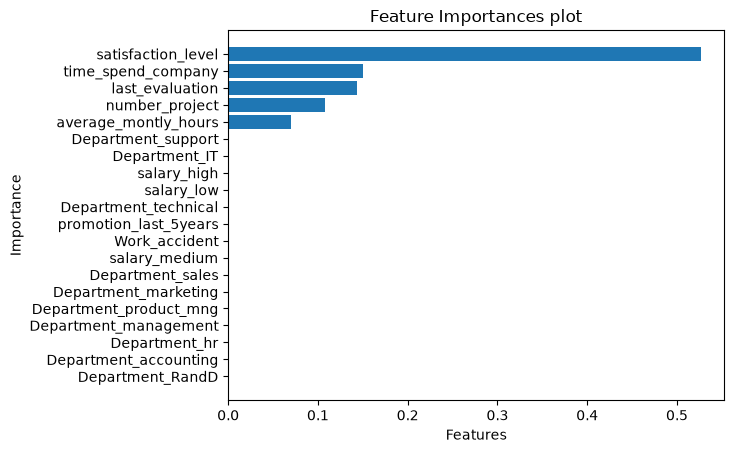

In [21]:
best_tree = DecisionTreeClassifier(random_state=26, max_depth = 7, min_samples_split= 2, min_samples_leaf= 1)
x_ohe = ct.fit_transform(X)
best_tree.fit(x_ohe, y)
df_imp = pd.DataFrame({'features': list(x_ohe.columns),
                       'importance': best_tree.feature_importances_})
df_imp.sort_values('importance', inplace = True)
plt.barh(df_imp['features'], df_imp['importance'])
plt.title("Feature Importances plot")
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()